Task 3.1 — Convolution from the definition

verifying pre lab(a):

In [1]:
import numpy as np

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))             # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]


In [2]:
import time
import numpy as np

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

t0 = time.perf_counter()
y1 = conv(a, b)
t_conv = time.perf_counter() - t0

t0 = time.perf_counter()
y2 = np.convolve(a, b)
t_np = time.perf_counter() - t0

print(f"conv        : {t_conv:.4f} s")
print(f"np.convolve : {t_np:.6f} s")
print(f"speed-up    : {t_conv/t_np:.0f}x")
print("same result :", np.allclose(y1, y2))

conv        : 2.9054 s
np.convolve : 0.004840 s
speed-up    : 600x
same result : True


Task 3.1: Convolution from the definition

Method:
conv(x, h) implements y[n] = sum_k x[k]*h[n-k] for n = 0 ... len(x)+len(h)-2,
adding a term only when 0 <= n-k < len(h).

Verification:
For x = [1, 2, 3, 1] and h = [1, 1, 1], conv gives [1 3 6 6 4 1], and
np.convolve gives the same values, which agrees with my pre-lab answer (a).
(conv returns floats because it uses np.zeros, np.convolve returns integers.)

Timing (two random sequences of length 2000, time.perf_counter()):

  conv        : 2.9054s

  np.convolve : 0.004840s

  speed-up    : 600 x
  
  np.allclose(conv, np.convolve) : True

Discussion:
Both functions perform about N*M multiply-adds and give identical results.
np.convolve is much faster because it is compiled C code operating directly
on arrays, whereas conv runs an interpreted Python double loop and also tests
the index condition for every (n, k) pair.

Task 3.2 — Smoothing a noisy signal by convolution

M =  3 | residual noise+distortion RMS = 0.302 | peak amplitude = 1.966
M =  9 | residual noise+distortion RMS = 0.181 | peak amplitude = 1.369
M = 25 | residual noise+distortion RMS = 0.274 | peak amplitude = 0.758
noisy x: RMS error = 0.509


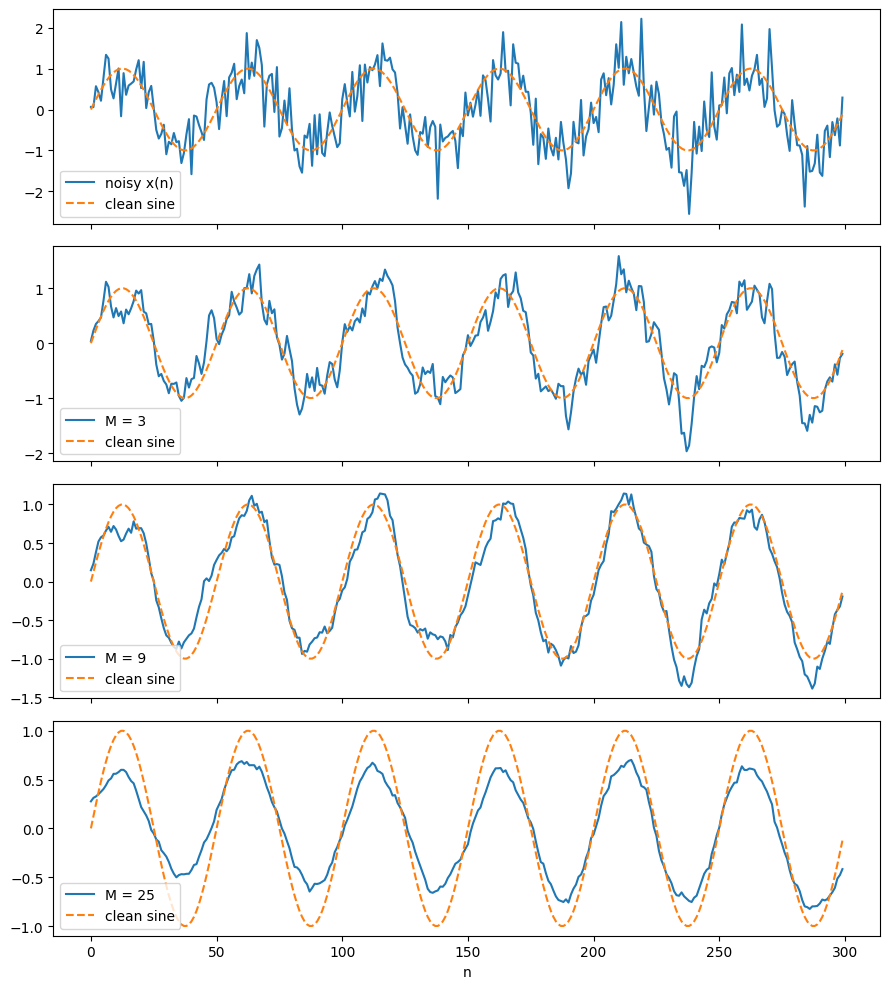

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)

fig, axs = plt.subplots(4, 1, figsize=(9, 10), sharex=True)
axs[0].plot(n, x, label="noisy x(n)"); axs[0].plot(n, clean, "--", label="clean sine"); axs[0].legend()

for ax, M in zip(axs[1:], [3, 9, 25]):
    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")
    ax.plot(n, y, label=f"M = {M}"); ax.plot(n, clean, "--", label="clean sine"); ax.legend()
    mid = slice(30, -30)                          # skip edges (zero-padding effect)
    print(f"M = {M:2d} | residual noise+distortion RMS = {np.std(y[mid]-clean[mid]):.3f}"
          f" | peak amplitude = {np.max(np.abs(y[mid])):.3f}")

print(f"noisy x: RMS error = {np.std(x-clean):.3f}")
axs[-1].set_xlabel("n"); plt.tight_layout(); plt.show()

Task 3.2: Smoothing a noisy signal by convolution

x(n) = sin(2*pi*n/50) + 0.5*w(n), 0 <= n < 300, was convolved with moving-
average filters h = (1/M)*[1,...,1] for M = 3, 9, 25 (mode="same").

Trade-off: for white noise, averaging M samples reduces the noise standard
deviation by about 1/sqrt(M) (0.5 -> 0.29, 0.17, 0.10), so a larger M gives a
cleaner signal. But the moving average is a low-pass filter, and its gain at
the sine frequency is |sin(M*w/2)/(M*sin(w/2))|, w = 2*pi/50. This is about
0.995 for M = 3, 0.948 for M = 9 and 0.637 for M = 25, so the wanted signal
is also attenuated (amplitude distortion), and sharp features would be
smeared. Small M keeps the signal but leaves more noise; large M removes
noise but distorts the signal. M = 9 is a good compromise here.

Near both ends the output is distorted because of zero padding.

Task 3.3 — Testing linearity and time-invariance numerically

In [4]:
import numpy as np

rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]      # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]   # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear}  time-invariant={tinv}")

x^2             linear=False  time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True


Task 3.3: Testing linearity and time-invariance

Definitions (handout 1.7): T is linear if T{a*x1 + b*x2} = a*T{x1} + b*T{x2};
T is time-invariant if a delay of the input by n0 delays the output by n0.


y = x^2: linear = False, time-invariant = True. The square of a sum contains
the cross term 2ab*x1*x2, so superposition fails. The rule does not depend
on n, so a delayed input gives a delayed output.

y = n*x(n): linear = True, time-invariant = False. Multiplying by n
distributes over sums and scaling. But the gain n changes with time: the
delayed input gives n*x1(n-5), while the delayed output is (n-5)*x1(n-5).
Moving average: linear = True, time-invariant = True. It is a convolution
with a fixed impulse response, i.e. an LTI system.

Task 3.4 — Finding a hidden delay with cross-correlation

sigma = 0.5 | estimated delay = 37 samples = 37.0 ms | one-way distance = 12.69 m
sigma =   1 | estimated delay = 37 samples = 37.0 ms | one-way distance = 12.69 m
sigma =   2 | estimated delay = 37 samples = 37.0 ms | one-way distance = 12.69 m
sigma =   4 | estimated delay = 87 samples = 87.0 ms | one-way distance = 29.84 m


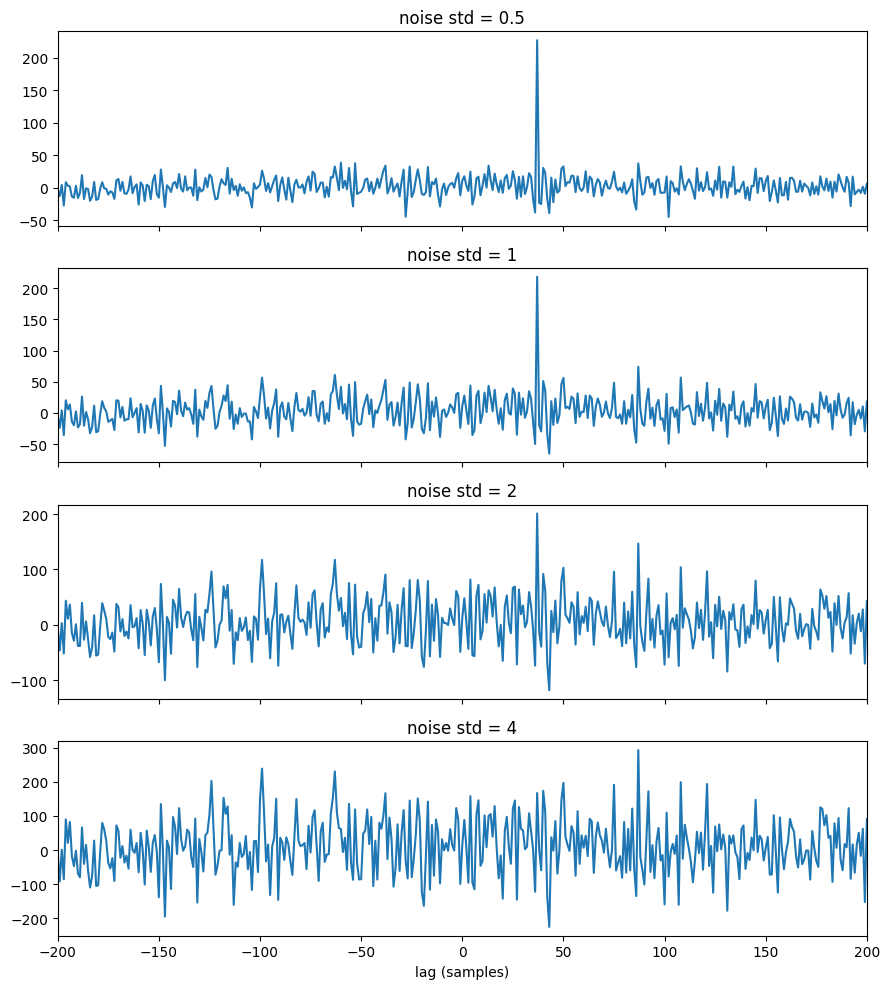


Success rate over 200 random trials:
sigma = 0.5 | correct in 200/200 trials
sigma =   1 | correct in 200/200 trials
sigma =   2 | correct in 200/200 trials
sigma =   4 | correct in 129/200 trials
sigma =   6 | correct in 50/200 trials
sigma =   8 | correct in 22/200 trials


In [5]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

fs = 1000
true_delay = 37

def estimate(sigma, seed):
    rng = np.random.default_rng(seed)
    x = rng.standard_normal(500)                                   # transmitted signal
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    return lags, r, lags[np.argmax(r)]

fig, axs = plt.subplots(4, 1, figsize=(9, 10), sharex=True)
for ax, sigma in zip(axs, [0.5, 1, 2, 4]):
    lags, r, est = estimate(sigma, seed=1)
    d = est / fs * 343
    print(f"sigma = {sigma:3} | estimated delay = {est} samples = {est/fs*1000:.1f} ms"
          f" | one-way distance = {d:.2f} m")
    ax.plot(lags, r); ax.set_xlim(-200, 200); ax.set_title(f"noise std = {sigma}")
axs[-1].set_xlabel("lag (samples)"); plt.tight_layout(); plt.show()

print("\nSuccess rate over 200 random trials:")
for sigma in [0.5, 1, 2, 4, 6, 8]:
    ok = sum(estimate(sigma, s)[2] == true_delay for s in range(200))
    print(f"sigma = {sigma:3} | correct in {ok}/200 trials")

Task 3.4: Finding a hidden delay with cross-correlation

The received signal is y(n) = 0.6*x(n - 37) + sigma*w(n). The lag of the
maximum of the cross-correlation r = correlate(y, x) estimates the delay.
Results (seed 1):

Success rate over 200 random trials:

sigma = 0.5 | correct in 200/200 trials

sigma =   1 | correct in 200/200 trials

sigma =   2 | correct in 200/200 trials

sigma =   4 | correct in 129/200 trials

sigma =   6 | correct in 50/200 trials

sigma =   8 | correct in 22/200 trials


Why: the correlation peak is about 0.6*sum(x^2) = 300, while the noise
contributes about sigma*sqrt(500) = 22*sigma at each lag. Detection fails
when the largest of ~1000 noise values reaches the peak, i.e. when the
peak is only about 3 noise standard deviations high (sigma around 4).
The estimate fails at noise level sigma ~ ___ (from my experiment).

Distance: delay = 37/1000 s = 0.037 s. Distance = 343 m/s * 0.037 s
= 12.69 m (one way); if the pulse travelled there and back, the
distance is 6.35 m.